# FLIP: Common-protocol comparison of universal triggers

**Sub-question 1.** *How do the surrogate architecture and the training objective influence the generated triggers, and does this change FLIP's poisoning efficiency?*

We replace FLIP's handcrafted sinusoidal trigger (`1xs`) with one **universal** perturbation δ ∈ ℝ^{3×32×32}, learned by a GAN and added to every truck image. ‖δ‖∞ ≤ ε = 6/255 is enforced inside the generator (ε·tanh), so all triggers satisfy the same constraint as the sinusoid.

**Shared protocol**
* CIFAR-10, source truck = 9, target deer = 4; universal bounded trigger with nominal \(\|\delta\|_\infty\leq6/255\).
* Expert: ResNet-32, 20 epochs, 5 training seeds (0–4); fixed FLIP optimization seed 0.
* FLIP budgets: 300, 500, 1,000, 1,500 hard-label flips per Expert.
* Victim: ResNet-32, 100 epochs, 5 training seeds (0–4); all Victims of a method share labels from Expert seed 0.

$$L_G = \lambda_{\text{adv}}\,L_{\text{adv}} + \lambda_{\text{tgt}}\,L_{\text{tgt}},\qquad L_{\text{tgt}} = \frac{1}{|\mathcal S|}\sum_{s\in\mathcal S}\mathrm{CE}\big(s(x+\delta),\ \text{deer}\big)$$


In [18]:
from pathlib import Path
import sys, json, hashlib, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

start = Path.cwd().resolve()
ROOT = next((p for p in [start, *start.parents] if (p / 'run_experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from ~/projects/FLIP (or a subfolder) on the Polytechnique server.')
sys.path[:0] = [str(ROOT), str(ROOT / 'modules')]
EXP = ROOT / 'experiments'; NOISE = ROOT / 'noise_generator'
FIG = ROOT / 'figures/exp1_common_analysis'
OUT = ROOT / 'results/exp1_common_analysis'
FIG.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
BUDGETS = [300, 500, 1000, 1500]
SEEDS = list(range(5)); SRC, TGT = 9, 4
METHODS = {
 'sin':       dict(label='Sinusoidal',       root='exp1_sinusoidal_common', prefix='sin',       flag='1xs',          delta=None),
 'r32':       dict(label='GAN–R32',         root='exp1_r32_common',        prefix='r32',       flag='1xg',          delta='universal_delta.npy'),
 'r18':       dict(label='GAN–R18',         root='exp1_r18_common',        prefix='r18',       flag='1xg_r18',      delta='universal_delta_r18.npy'),
 'effnet':    dict(label='GAN–EfficientNet',root='exp1_effnet_common',     prefix='effnet',    flag='1xg_effnet',   delta='universal_delta_effnet.npy'),
 'notarget':  dict(label='GAN–NoTarget',    root='exp1_notarget_common',   prefix='notarget',  flag='1xg_notarget', delta='universal_delta_notarget.npy'),
 'vit':       dict(label='GAN–ViT',         root='exp1_vit_common',        prefix='vit',       flag='1xg_vit',      delta='universal_delta_vit.npy'),
}
COLOR = dict(zip(METHODS, plt.get_cmap('tab10').colors[:len(METHODS)]))
plt.rcParams.update({'figure.dpi':115, 'savefig.dpi':220, 'font.size':10,
                     'axes.spines.right':False,'axes.spines.top':False,
                     'axes.grid':True, 'grid.alpha':.17})

def save_figure(fig, basename):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG/f'{basename}.{ext}', bbox_inches='tight', dpi=220)
    print('Saved figure:', basename)

def save_table(df, basename):
    df.to_csv(OUT/f'{basename}.csv',index=False)
    print('Saved table:', basename)

def folder(v, b, s):
    m = METHODS[v]
    return EXP/m['root']/f"{m['prefix']}_b{b}_u{s}"

def load_run(v,b,s):
    d = folder(v,b,s)
    a,bp = d/'caccs.npy',d/'paccs.npy'
    if not (a.is_file() and bp.is_file()): return None
    ca,pa=np.load(a, allow_pickle=False),np.load(bp, allow_pickle=False)
    if ca.ndim != 2 or pa.ndim != 2 or ca.shape[1] < 1 or pa.shape[1] < 1:
        raise ValueError(f'Unexpected metric shape: {d}: {ca.shape}, {pa.shape}')
    if len(ca)!=100 or len(pa)!=100:
        warnings.warn(f'{d}: expected 100 evaluation epochs; found {len(ca)} and {len(pa)}')
    # Source: compare_triggers.ipynb and universal_noise_gan.ipynb, victim_metrics().
    # COLUMN 0 is ACCURACY, in [0,1]; COLUMN 1 IS NOT CTA/PTA.
    ccurve=100*np.asarray(ca[:,0],dtype=float)
    pcurve=100*np.asarray(pa[:,0],dtype=float)
    if not (np.isfinite(ccurve).all() and np.isfinite(pcurve).all()):
        raise ValueError(f'Nonfinite accuracy values in {d}')
    if np.min(ccurve)<-1e-6 or np.max(ccurve)>100.0001 or np.min(pcurve)<-1e-6 or np.max(pcurve)>100.0001:
        raise ValueError(f'Out-of-range percentage accuracies in {d}')
    return dict(CTA=float(ccurve[-1]), PTA=float(pcurve[-1]), cta_curve=ccurve, pta_curve=pcurve)

print('Root:',ROOT)
print('Figures:',FIG)
print('Tables:',OUT)

Root: /users/eleves-b/2026/beatrice.camera/projects/FLIP
Figures: /users/eleves-b/2026/beatrice.camera/projects/FLIP/figures/exp1_common_analysis
Tables: /users/eleves-b/2026/beatrice.camera/projects/FLIP/results/exp1_common_analysis


## Inventory and exact saved-metric definitions

In [19]:
records=[]; CURVES={}
for v,m in METHODS.items():
    for b in BUDGETS:
        for s in SEEDS:
            run=load_run(v,b,s)
            records.append(dict(variant=v,method=m['label'],budget=b,seed=s,
                                complete=run is not None,
                                CTA=np.nan if run is None else run['CTA'],
                                PTA=np.nan if run is None else run['PTA']))
            if run: CURVES[(v,b,s)] = run
RUNS=pd.DataFrame(records)
READY=[v for v in METHODS if RUNS.loc[RUNS.variant.eq(v),'complete'].all()]
PARTIAL=[v for v in METHODS if v not in READY and RUNS.loc[RUNS.variant.eq(v),'complete'].any()]
PENDING=[v for v in METHODS if v not in READY and v not in PARTIAL]
status=[]
for v,m in METHODS.items():
    root=EXP/m['root']; ck=ROOT/'out/checkpoints'/m['root']
    experts=sum((ck/f"{m['prefix']}_f{s}"/'0'/'model_20_200.pth').stat().st_size>0
                for s in SEEDS if (ck/f"{m['prefix']}_f{s}"/'0'/'model_20_200.pth').is_file())
    flips=sum((root/f"{m['prefix']}_f{s}_labels"/f'{b}.npy').is_file() for s in SEEDS for b in BUDGETS)
    victims=int(RUNS.loc[RUNS.variant.eq(v),'complete'].sum())
    status.append(dict(method=m['label'],experts=f'{experts}/5',FLIP=f'{flips}/20',victims=f'{victims}/20'))
STATUS=pd.DataFrame(status)
display(STATUS)
print('Fully complete:',[METHODS[v]['label'] for v in READY]);print('Partially complete:',PARTIAL);print('Pending:',PENDING)
assert RUNS['CTA'].dropna().between(0,100).all()
assert RUNS['PTA'].dropna().between(0,100).all()
save_table(STATUS,'00_completion_status')
save_table(RUNS,'01_victim_per_seed')

AGG=(RUNS[RUNS.complete].groupby(['variant','method','budget'],sort=False)
     .agg(CTA_mean=('CTA','mean'),CTA_sd=('CTA','std'),PTA_mean=('PTA','mean'),PTA_sd=('PTA','std'),n=('seed','size'))
     .reset_index())
display(AGG.round(2));save_table(AGG,'02_budget_mean_sd')

,method,experts,FLIP,victims
0,Sinusoidal,5/5,20/20,20/20
1,GAN–R32,5/5,20/20,20/20
2,GAN–R18,5/5,20/20,20/20
3,GAN–EfficientNet,5/5,20/20,20/20
4,GAN–NoTarget,5/5,20/20,20/20
5,GAN–ViT,0/5,0/20,0/20


Fully complete: ['Sinusoidal', 'GAN–R32', 'GAN–R18', 'GAN–EfficientNet', 'GAN–NoTarget']
Partially complete: []
Pending: ['vit']
Saved table: 00_completion_status
Saved table: 01_victim_per_seed


,variant,method,budget,CTA_mean,CTA_sd,PTA_mean,PTA_sd,n
0,sin,Sinusoidal,300,91.57,0.25,22.80,10.99,5
1,sin,Sinusoidal,500,91.23,0.18,62.86,8.02,5
2,sin,Sinusoidal,1000,90.52,0.56,91.08,6.17,5
3,sin,Sinusoidal,1500,89.61,0.55,96.86,2.54,5
4,r32,GAN–R32,300,91.44,0.27,72.16,10.29,5
5,r32,GAN–R32,500,91.26,0.52,83.64,9.03,5
6,r32,GAN–R32,1000,90.61,0.31,97.96,0.56,5
7,r32,GAN–R32,1500,89.71,0.25,99.46,0.49,5
8,r18,GAN–R18,300,91.77,0.34,97.76,1.31,5
9,r18,GAN–R18,500,91.44,0.20,99.92,0.18,5


Saved table: 02_budget_mean_sd


## CTA and PTA versus poisoning budget

Saved figure: fig01_cta_by_budget


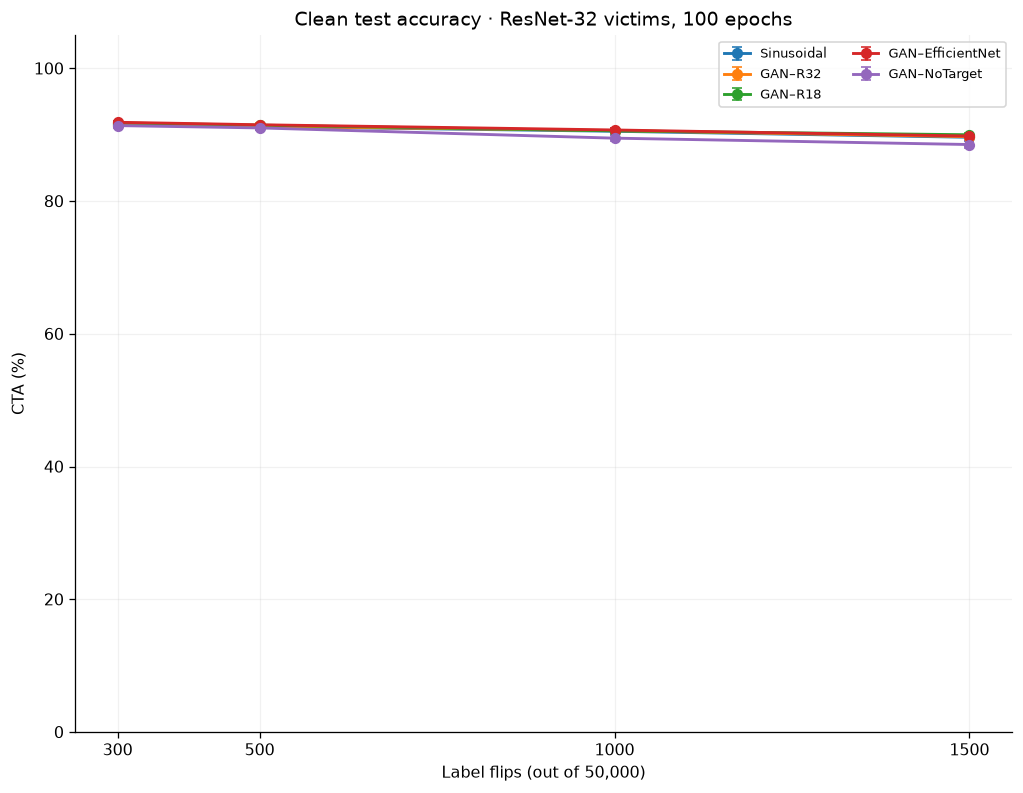

Saved figure: fig02_pta_by_budget


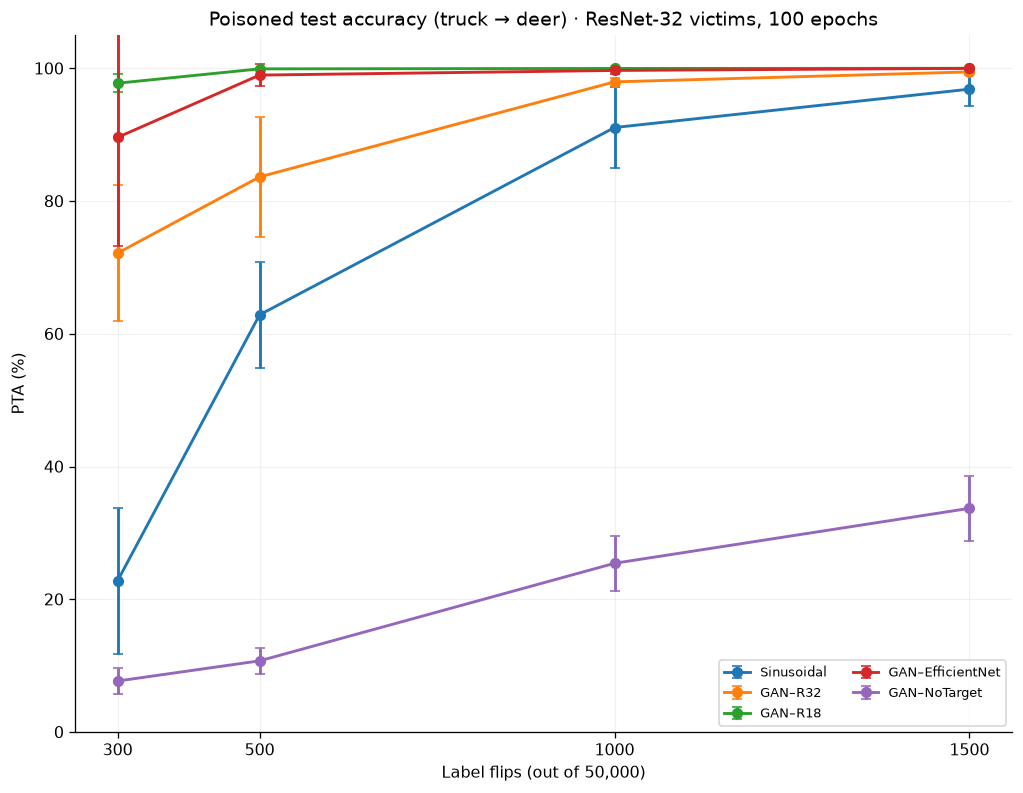

In [20]:
for metric,title,filename in [('CTA','Clean test accuracy','fig01_cta_by_budget'),
                              ('PTA','Poisoned test accuracy (truck → deer)','fig02_pta_by_budget')]:
    fig,ax=plt.subplots(figsize=(9,7))
    for v in METHODS:
        sub=AGG[AGG.variant.eq(v)].sort_values('budget')
        if sub.empty: continue
        ax.errorbar(sub.budget,sub[f'{metric}_mean'],yerr=sub[f'{metric}_sd'].fillna(0),
                    label=METHODS[v]['label'],color=COLOR[v],marker='o',capsize=3,lw=1.8)
    ax.set_xticks(BUDGETS);ax.set_xlabel('Label flips (out of 50,000)');ax.set_ylabel(f'{metric} (%)')
    ax.set_title(title+' · ResNet-32 victims, 100 epochs')
    ax.set_ylim(0,105)
    ax.legend(loc='best',fontsize=8,ncol=2)
    fig.tight_layout();save_figure(fig,filename);plt.show()

## PTA and CTA evolution during Victim training

Saved figure: fig03_pta_by_epoch


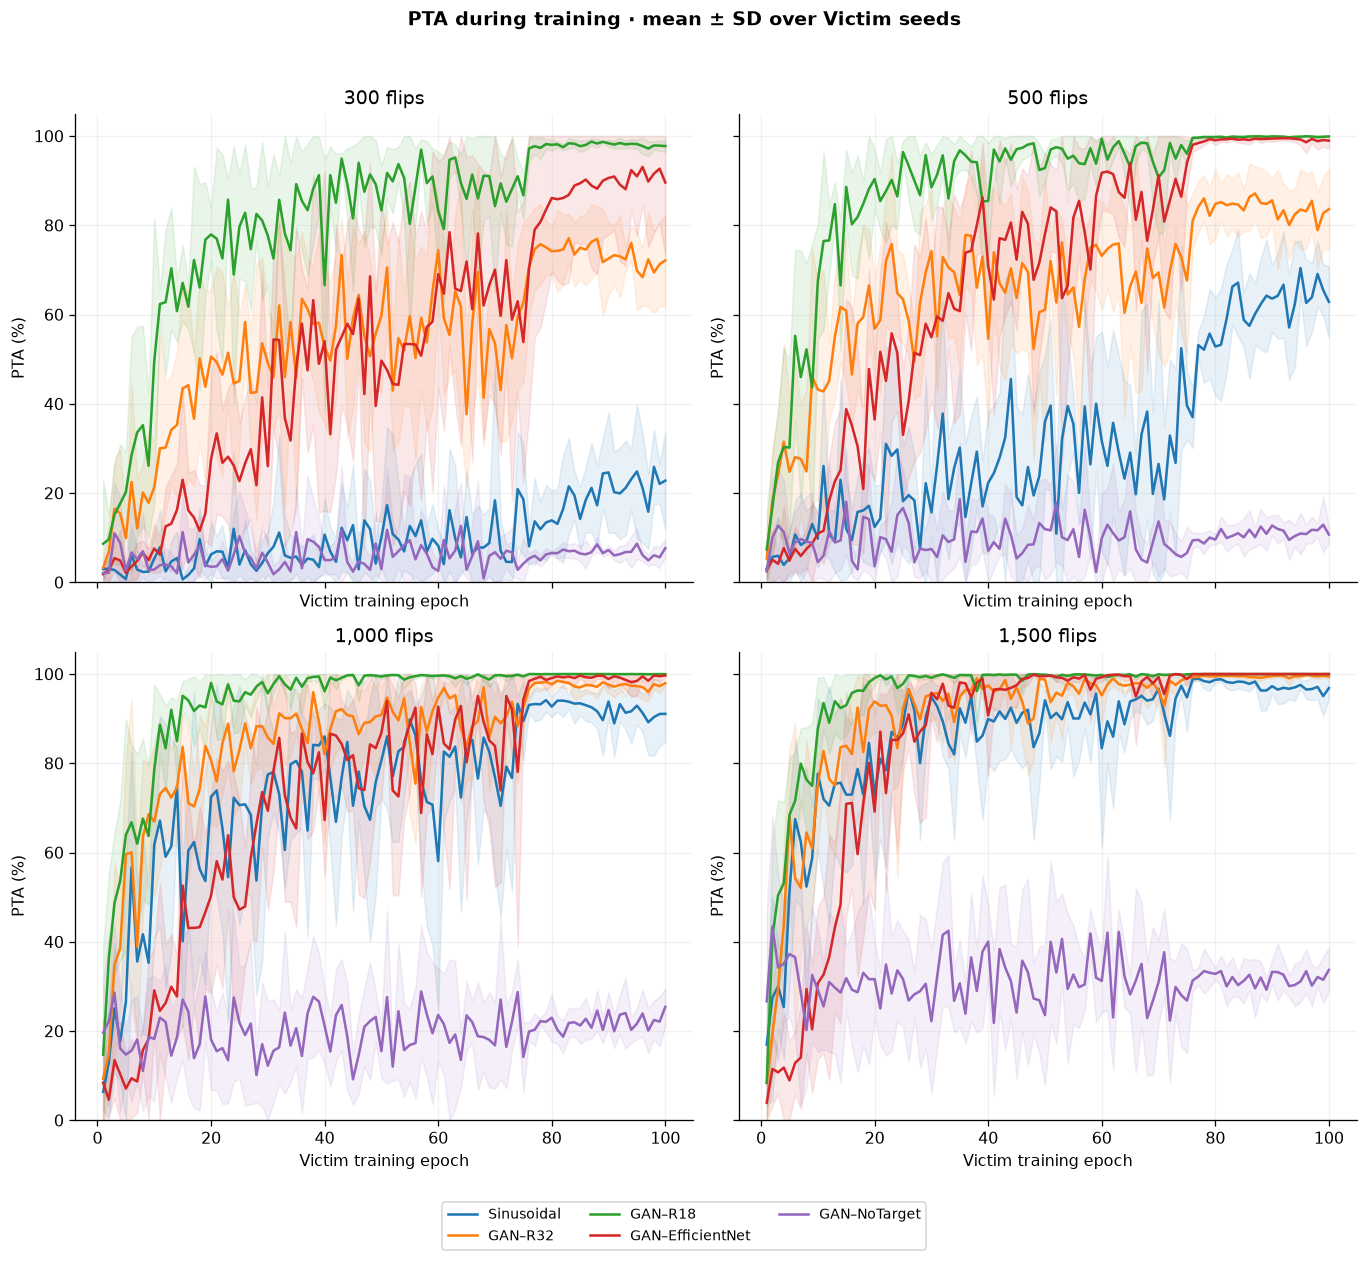

Saved figure: fig04_cta_by_epoch


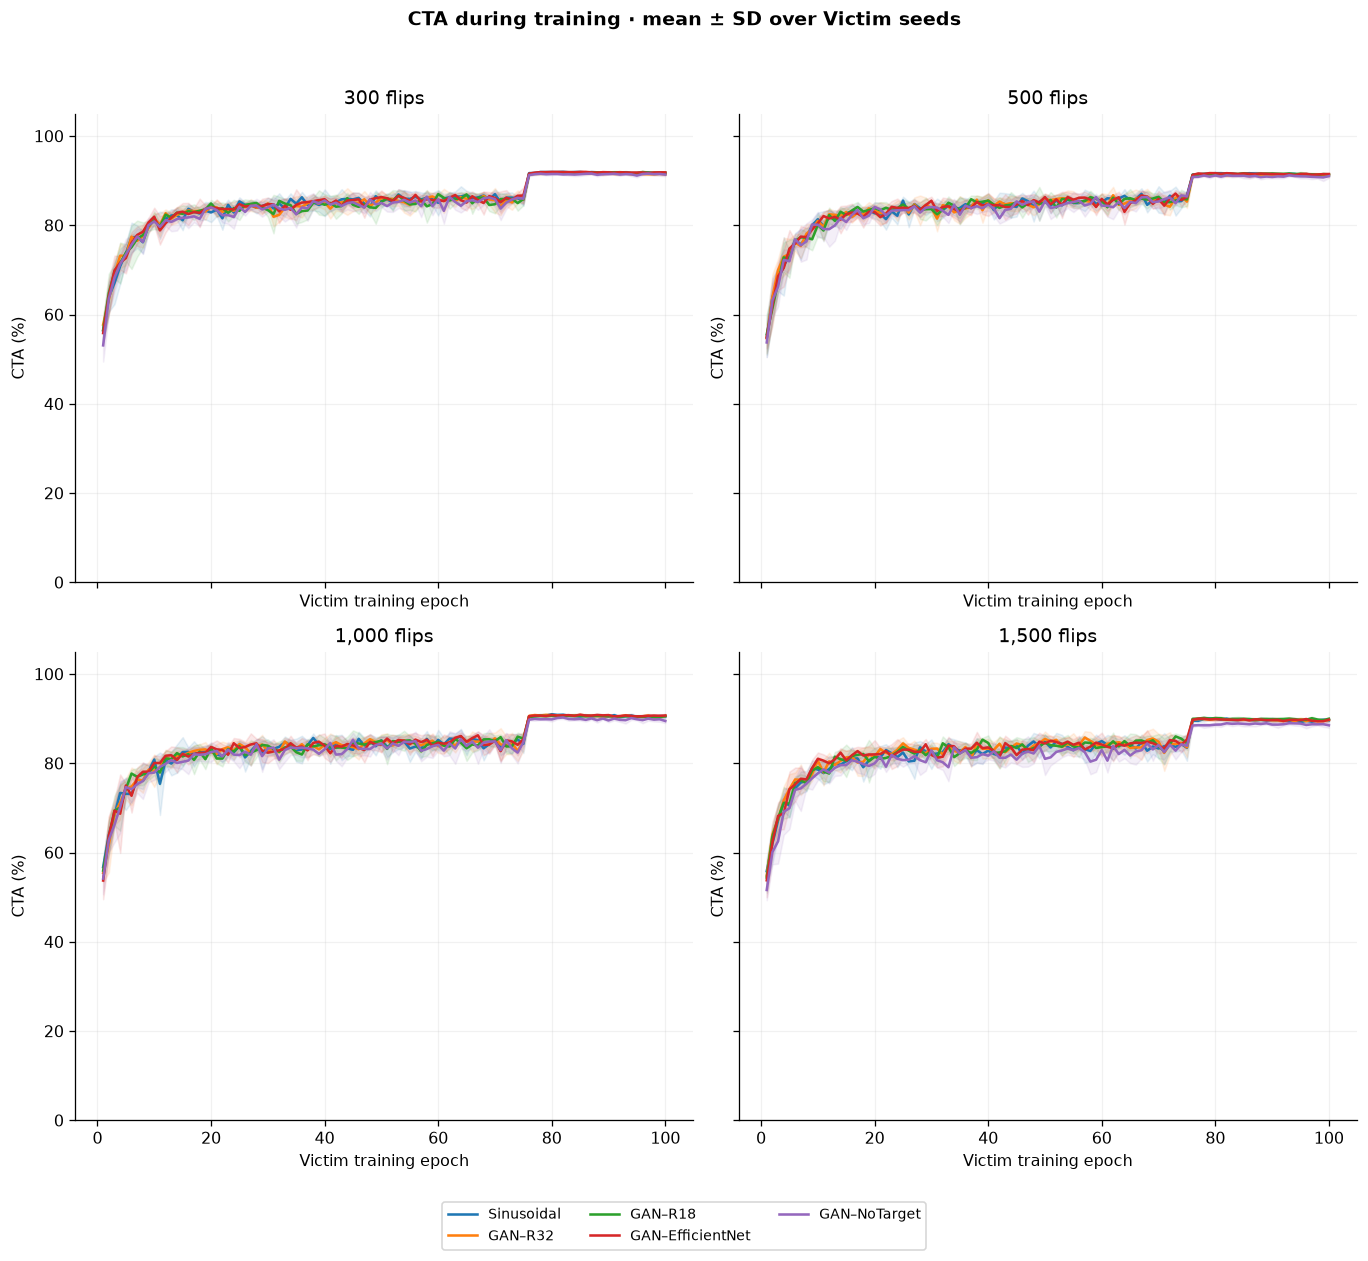

In [21]:
for metric in ('PTA','CTA'):
    fig,axes=plt.subplots(2,2,figsize=(12,11),sharex=True,sharey=True)
    for ax,b in zip(axes.flat,BUDGETS):
        for v in METHODS:
            arrs=[CURVES[(v,b,s)][metric.lower()+'_curve'] for s in SEEDS if (v,b,s) in CURVES]
            if not arrs: continue
            length=min(map(len,arrs));a=np.stack([x[:length] for x in arrs])
            x=np.arange(1,length+1);mu=a.mean(0);sd=a.std(0,ddof=1) if len(a)>1 else np.zeros(length)
            ax.plot(x,mu,label=METHODS[v]['label'],color=COLOR[v],lw=1.6)
            ax.fill_between(x,np.clip(mu-sd,0,100),np.clip(mu+sd,0,100),color=COLOR[v],alpha=.10)
        ax.set_title(f'{b:,} flips');ax.set_ylim(0,105)
        ax.set_xlabel('Victim training epoch');ax.set_ylabel(f'{metric} (%)')
    handles,labels=axes.flat[0].get_legend_handles_labels()
    fig.legend(handles,labels,loc='lower center',ncol=3,bbox_to_anchor=(.5,-.005),fontsize=9)
    fig.suptitle(f'{metric} during training · mean ± SD over Victim seeds',fontweight='bold')
    fig.tight_layout(rect=(0,.05,1,.96))
    save_figure(fig,f'fig0{3 if metric=="PTA" else 4}_{metric.lower()}_by_epoch');plt.show()

Saved figure: fig11_cta_barplot


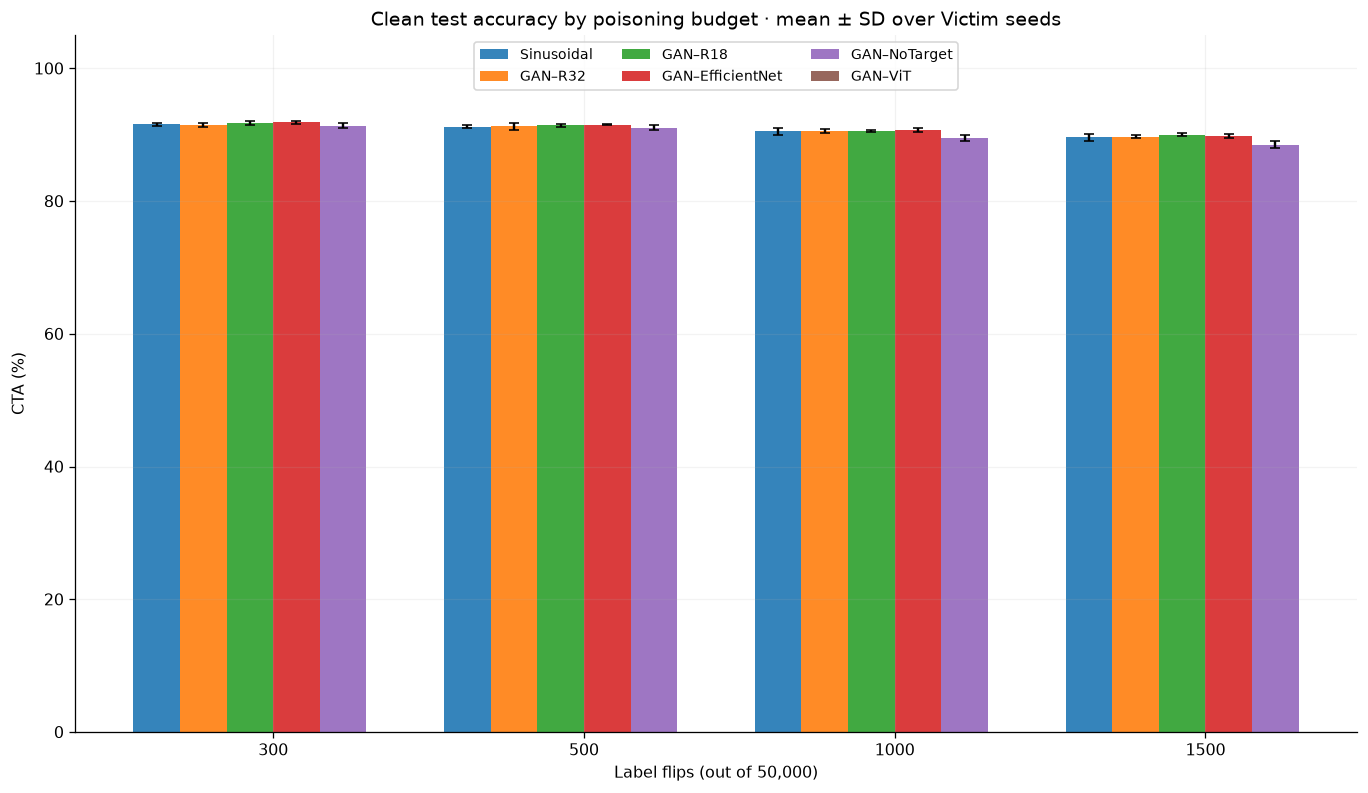

Saved figure: fig12_pta_barplot


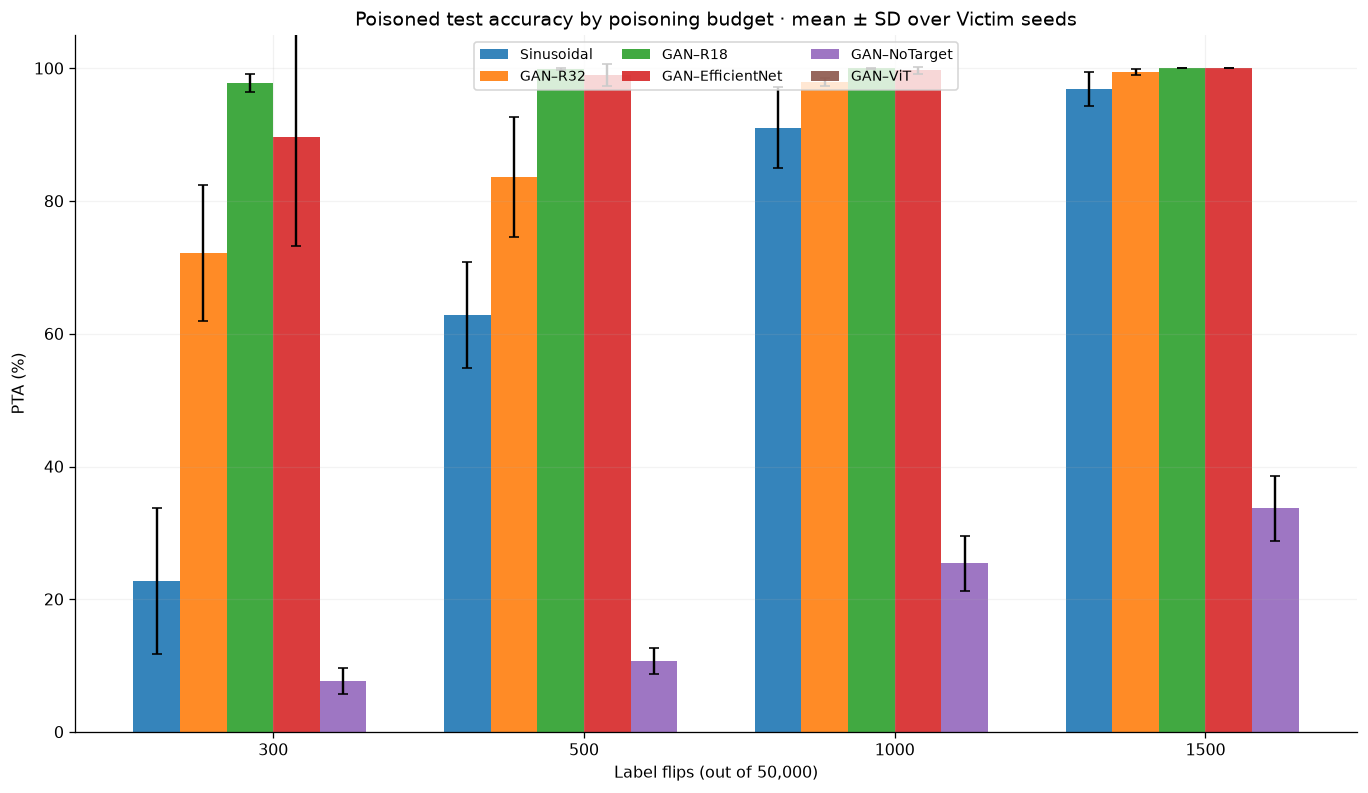

In [28]:
width=.15
for metric,title,filename in [('CTA','Clean test accuracy','fig11_cta_barplot'),
                              ('PTA','Poisoned test accuracy','fig12_pta_barplot')]:
    fig,ax=plt.subplots(figsize=(12,7))
    x=np.arange(len(BUDGETS))
    for i,v in enumerate(METHODS):
        sub=AGG[AGG.variant.eq(v)].set_index('budget').reindex(BUDGETS)
        pos=x+(i-(len(METHODS)-1)/2)*width
        ax.bar(pos,sub[f'{metric}_mean'],width,yerr=sub[f'{metric}_sd'].fillna(0),
               label=METHODS[v]['label'],color=COLOR[v],capsize=3,alpha=.9)
    ax.set_xticks(x,BUDGETS)
    ax.set(xlabel='Label flips (out of 50,000)',ylabel=f'{metric} (%)',
           title=f'{title} by poisoning budget · mean ± SD over Victim seeds')
    ax.set_ylim(0,105)
    ax.legend(ncol=3,fontsize=9,loc='upper center')
    ax.grid(axis='y',alpha=.15)
    fig.tight_layout();save_figure(fig,filename);plt.show()

## CTA–PTA trade-off

Saved figure: fig05_cta_pta_tradeoff


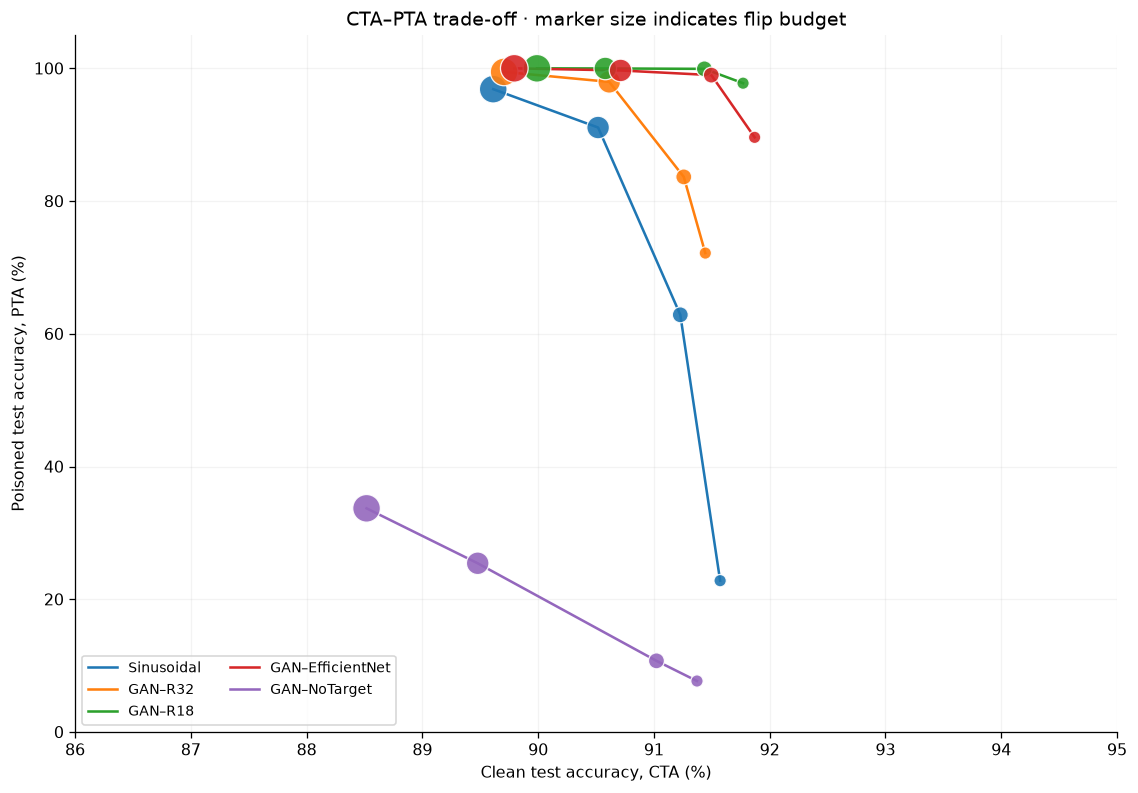

In [22]:
fig,ax=plt.subplots(figsize=(10,7))
for v in METHODS:
    sub=AGG[AGG.variant.eq(v)].sort_values('budget')
    if sub.empty: continue
    ax.plot(sub.CTA_mean,sub.PTA_mean,'-',color=COLOR[v],lw=1.6,label=METHODS[v]['label'])
    ax.scatter(sub.CTA_mean,sub.PTA_mean,s=sub.budget/5,color=COLOR[v],
               edgecolor='white',linewidth=.8,zorder=3,alpha=.9)

ax.set(xlabel='Clean test accuracy, CTA (%)',ylabel='Poisoned test accuracy, PTA (%)',
       xlim=(86,95),ylim=(0,105),title='CTA–PTA trade-off · marker size indicates flip budget')
ax.legend(ncol=2,fontsize=9,loc='lower left')
ax.grid(alpha=.15)
fig.tight_layout();save_figure(fig,'fig05_cta_pta_tradeoff');plt.show()

## Trigger images: original image, poisoned image, amplified noise

,variant,method,nominal_Linf_px,nominal_RMS_px,applied_Linf_px,applied_RMS_px
0,sin,Sinusoidal,NaN,NaN,6.0,4.076
1,r32,GAN–R32,6.000,5.912,6.0,5.895
2,r18,GAN–R18,6.000,5.873,6.0,5.845
3,effnet,GAN–EfficientNet,6.000,5.895,6.0,5.860
4,notarget,GAN–NoTarget,1.066,0.274,1.0,0.265
5,vit,GAN–ViT,6.000,5.889,6.0,5.846


Saved table: 03_trigger_magnitude
Saved figure: fig06_images_and_noise


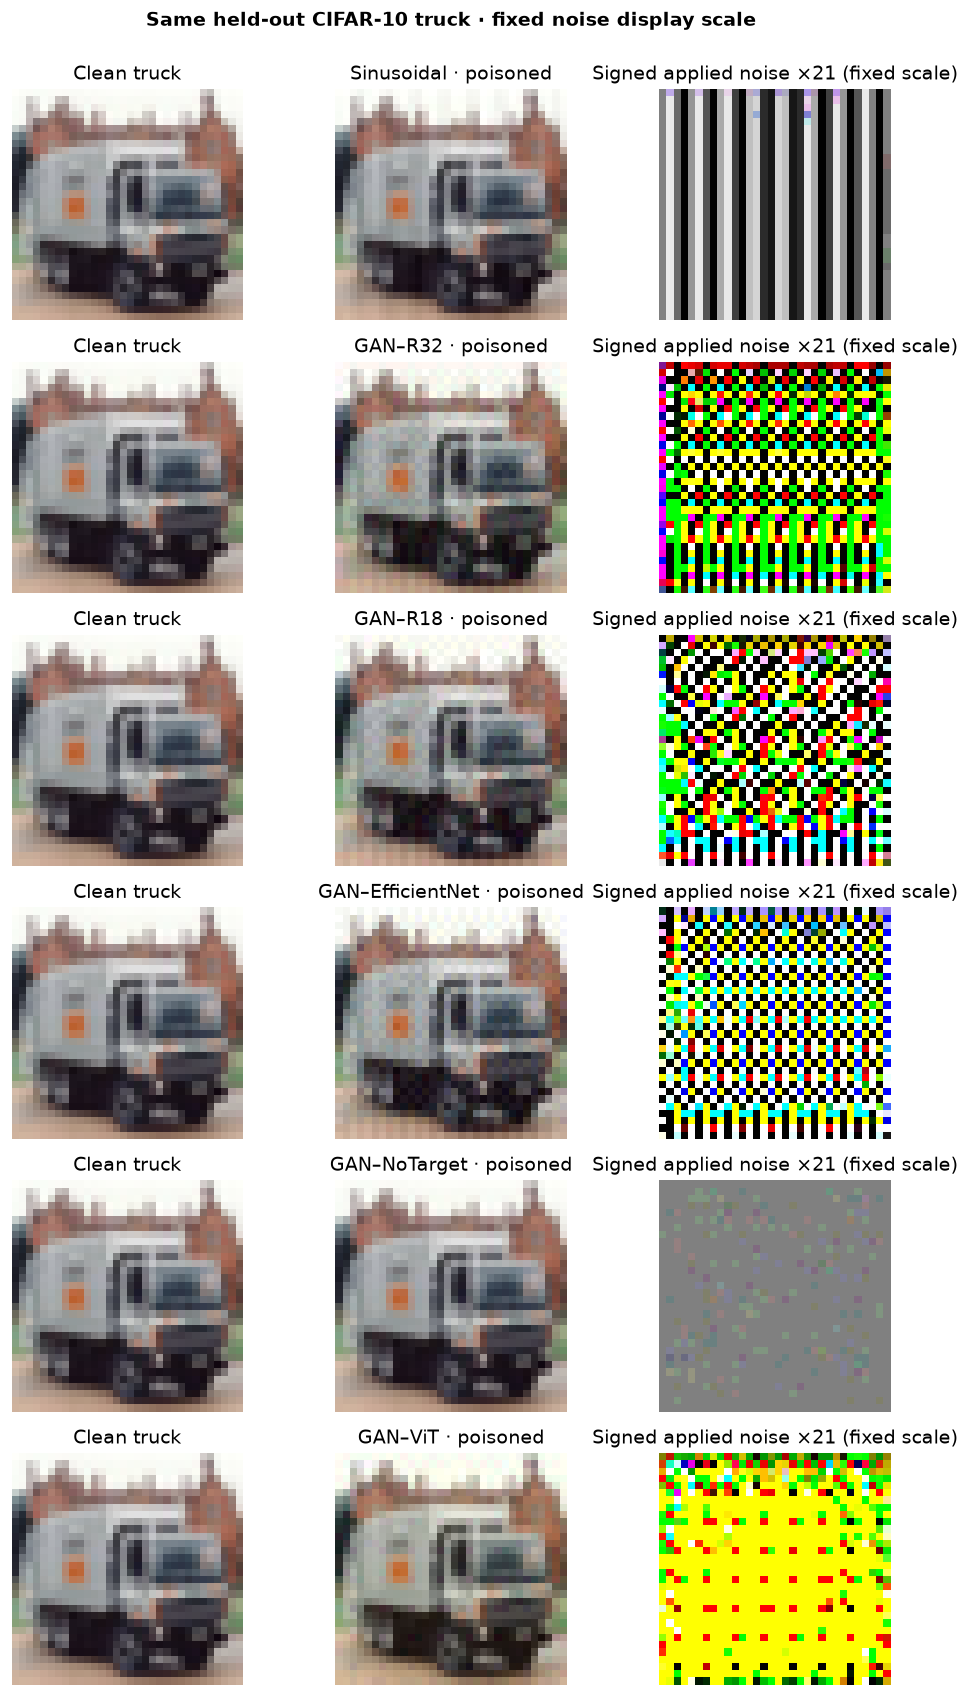

In [23]:
from torchvision.datasets import CIFAR10
from torchvision import transforms
from modules.base_utils.datasets import pick_poisoner
from PIL import Image

raw_test=CIFAR10(str(ROOT/'data/data_cifar10'),train=False,download=False)
truck_ids=[i for i,(_,y) in enumerate(raw_test) if y==SRC]
example_id=truck_ids[0]
original=raw_test[example_id][0].convert('RGB')
clean=np.asarray(original).astype(np.float32)
triggers={}; trig_stats=[]
for v,m in METHODS.items():
    path=NOISE/m['delta'] if m['delta'] is not None else None
    if path is not None and not path.is_file(): continue
    try:
        poisoned=pick_poisoner(m['flag'],'cifar',TGT).poisoner(original)
        arr=np.asarray(poisoned.convert('RGB')).astype(np.float32)
    except Exception as ex:
        print('Skip trigger:',v,repr(ex));continue
    diff=arr-clean
    triggers[v]=(arr,diff)
    if path is not None:
        delta=np.load(path,allow_pickle=False).astype(float)
        nominal_linf=float(np.abs(delta).max());nominal_rms=float(np.sqrt(np.mean(delta**2)))
    else: nominal_linf=float('nan');nominal_rms=float('nan')
    trig_stats.append(dict(variant=v,method=m['label'],
                           nominal_Linf_px=nominal_linf, nominal_RMS_px=nominal_rms,
                           applied_Linf_px=float(np.abs(diff).max()),
                           applied_RMS_px=float(np.sqrt(np.mean(diff**2)))))
TRIGGER=pd.DataFrame(trig_stats)
display(TRIGGER.round(3));save_table(TRIGGER,'03_trigger_magnitude')
if triggers:
    fig,axes=plt.subplots(len(triggers),3,figsize=(9,2.5*len(triggers)),squeeze=False)
    for axrow,(v,(arr,diff)) in zip(axes,triggers.items()):
        axrow[0].imshow(clean.astype('uint8'));axrow[0].set_title('Clean truck')
        axrow[1].imshow(arr.astype('uint8'));axrow[1].set_title(METHODS[v]['label']+' · poisoned')
        # Fixed visualization: zero=gray, saturation ±6px (consistent across methods).
        axrow[2].imshow(np.clip(diff/6*127+128,0,255).astype('uint8'))
        axrow[2].set_title('Signed applied noise ×21 (fixed scale)')
        for ax in axrow:ax.axis('off')
    fig.suptitle('Same held-out CIFAR-10 truck · fixed noise display scale',fontweight='bold')
    fig.tight_layout(rect=(0,0,1,.98));save_figure(fig,'fig06_images_and_noise');plt.show()

## Expert-model PTA / CTA table

In [24]:
import torch
from torch.utils.data import DataLoader
from modules.base_utils.util import load_model
from modules.base_utils.datasets import CIFAR_TRANSFORM_NORMALIZE

DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Expert evaluation device:',DEVICE)
normalize=CIFAR_TRANSFORM_NORMALIZE
cache_path=OUT/'04_expert_per_seed.csv'
old=pd.read_csv(cache_path) if cache_path.is_file() else pd.DataFrame()
cache={} if old.empty else {(r.variant,int(r.seed)):r._asdict() for r in old.itertuples(index=False)}

def file_fingerprint(paths):
    h=hashlib.sha256()
    for p in paths:
        p=Path(p);h.update(str(p).encode())
        if p.is_file():
            st=p.stat();h.update(str((st.st_size,st.st_mtime_ns)).encode())
            if p.suffix=='.npy':h.update(hashlib.sha256(p.read_bytes()).digest())
        else:h.update(b'MISSING')
    return h.hexdigest()

# Convert tensors once, outside Expert loop.
to_tensor=transforms.ToTensor()
clean_inputs=torch.stack([to_tensor(x) for x,_ in raw_test])
clean_labels=torch.tensor([y for _,y in raw_test],dtype=torch.long)
truck_pils=[raw_test[i][0] for i in truck_ids]
triggered_cache={}
def triggered_trucks(v):
    if v not in triggered_cache:
        poisoner=pick_poisoner(METHODS[v]['flag'],'cifar',TGT).poisoner
        triggered_cache[v]=torch.stack([to_tensor(poisoner(im)) for im in truck_pils])
    return triggered_cache[v]

@torch.inference_mode()
def predictions(model,images,batch_size=256):
    out=[]
    for start in range(0,len(images),batch_size):
        xb=normalize(images[start:start+batch_size].to(DEVICE))
        out.append(model(xb).argmax(1).cpu())
    return torch.cat(out)

expert_rows=[]
for v,m in METHODS.items():
    for s in SEEDS:
        checkpoint=ROOT/'out/checkpoints'/m['root']/f"{m['prefix']}_f{s}"/'0'/'model_20_200.pth'
        if not checkpoint.is_file() or checkpoint.stat().st_size==0:continue
        delta_path=NOISE/m['delta'] if m['delta'] else ROOT/'modules/base_utils/datasets.py'
        signature=file_fingerprint([checkpoint,delta_path])
        previous=cache.get((v,s))
        if previous is not None and previous.get('signature')==signature:
            expert_rows.append(previous);continue
        try:
            model=load_model('r32p',10).to(DEVICE)
            model.load_state_dict(torch.load(checkpoint,map_location=DEVICE,weights_only=True))
            model.eval()
            clean_pred=predictions(model,clean_inputs)
            poison_pred=predictions(model,triggered_trucks(v))
            row=dict(variant=v,method=m['label'],seed=s,
                     Expert_CTA=100*(clean_pred==clean_labels).float().mean().item(),
                     Expert_PTA=100*(poison_pred==TGT).float().mean().item(),
                     checkpoint=str(checkpoint.relative_to(ROOT)),signature=signature)
            expert_rows.append(row)
            print(f"{m['label']} Expert {s}: CTA {row['Expert_CTA']:.1f}%, PTA {row['Expert_PTA']:.1f}%")
        except Exception as ex:
            print('Expert evaluation failed',v,s,repr(ex))
        finally:
            try: del model
            except NameError:pass
            if torch.cuda.is_available(): torch.cuda.empty_cache()
EXPERT=pd.DataFrame(expert_rows)
if not EXPERT.empty:
    EXPERT=EXPERT.sort_values(['variant','seed']);save_table(EXPERT,'04_expert_per_seed')
    expert_summary=(EXPERT.groupby(['variant','method'],sort=False)
                    .agg(PTA_mean=('Expert_PTA','mean'),PTA_sd=('Expert_PTA','std'),
                         CTA_mean=('Expert_CTA','mean'),CTA_sd=('Expert_CTA','std'),n=('seed','size')).reset_index())
    display(EXPERT[['method','seed','Expert_PTA','Expert_CTA']].round(2))
    display(expert_summary.round(2));save_table(expert_summary,'05_expert_summary')
else:
    print('No evaluated Experts. Check GPU memory, checkpoint integrity and file availability.')

Expert evaluation device: cuda
Saved table: 04_expert_per_seed


,method,seed,Expert_PTA,Expert_CTA
15,GAN–EfficientNet,0,100.0,84.11
16,GAN–EfficientNet,1,100.0,84.51
17,GAN–EfficientNet,2,99.9,84.22
18,GAN–EfficientNet,3,99.4,84.81
19,GAN–EfficientNet,4,99.7,81.19
20,GAN–NoTarget,0,82.1,73.70
21,GAN–NoTarget,1,17.4,81.14
22,GAN–NoTarget,2,11.2,80.93
23,GAN–NoTarget,3,61.3,75.30
24,GAN–NoTarget,4,17.7,81.59


,variant,method,PTA_mean,PTA_sd,CTA_mean,CTA_sd,n
0,effnet,GAN–EfficientNet,99.80,0.25,83.77,1.47,5
1,notarget,GAN–NoTarget,37.94,31.79,78.53,3.73,5
2,r18,GAN–R18,99.94,0.13,83.46,1.43,5
3,r32,GAN–R32,99.88,0.16,81.73,2.12,5
4,sin,Sinusoidal,98.88,1.69,83.45,1.85,5


Saved table: 05_expert_summary


## FLIP label solution: composition and overlap

**Composition**: which true labels are changed into which others at each budget (particularly truck→deer). 

**Overlap**: Jaccard similarity of selected indices for different methods at matched Expert seeds (off-diagonal); diagonal compares different Expert seeds of the same method.

n_flipped  truck→deer
method           budget                       
GAN–EfficientNet 300         300.0       198.4
                 500         500.0       300.0
                 1000       1000.0       469.2
                 1500       1500.0       587.0
GAN–NoTarget     300         300.0       300.0
                 500         500.0       500.0
                 1000       1000.0      1000.0
                 1500       1500.0      1500.0
GAN–R18          300         300.0       248.8
                 500         500.0       377.0
                 1000       1000.0       606.8
                 1500       1500.0       758.6
GAN–R32          300         300.0       257.6
                 500         500.0       381.2
                 1000       1000.0       581.0
                 1500       1500.0       715.0
Sinusoidal       300         300.0       282.6
                 500         500.0       459.0
                 1000       1000.0       830.2
                 1500       1500.0      1065.0

Saved table: 06_flip_composition_per_expert
Saved figure: fig07_label_solution_composition


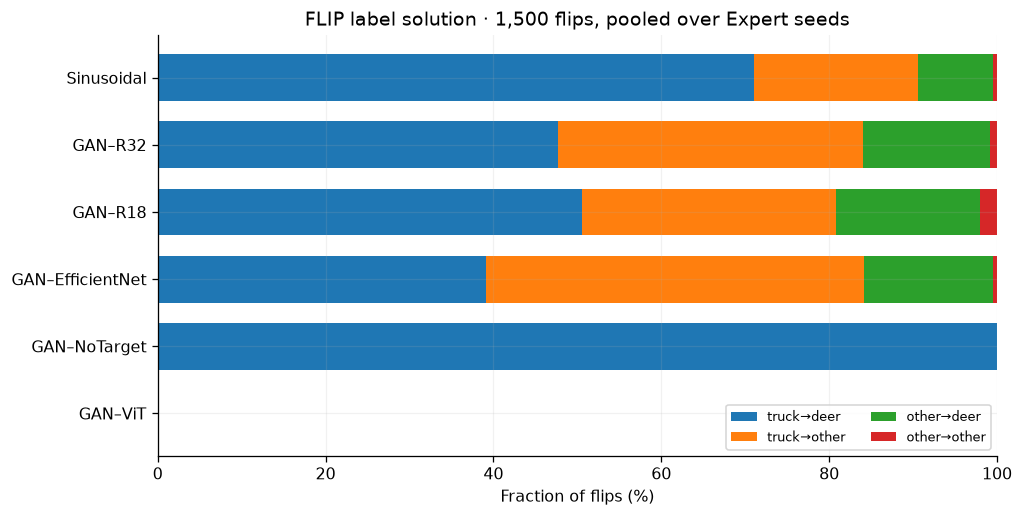

Saved figure: fig08_flip_overlap_jaccard


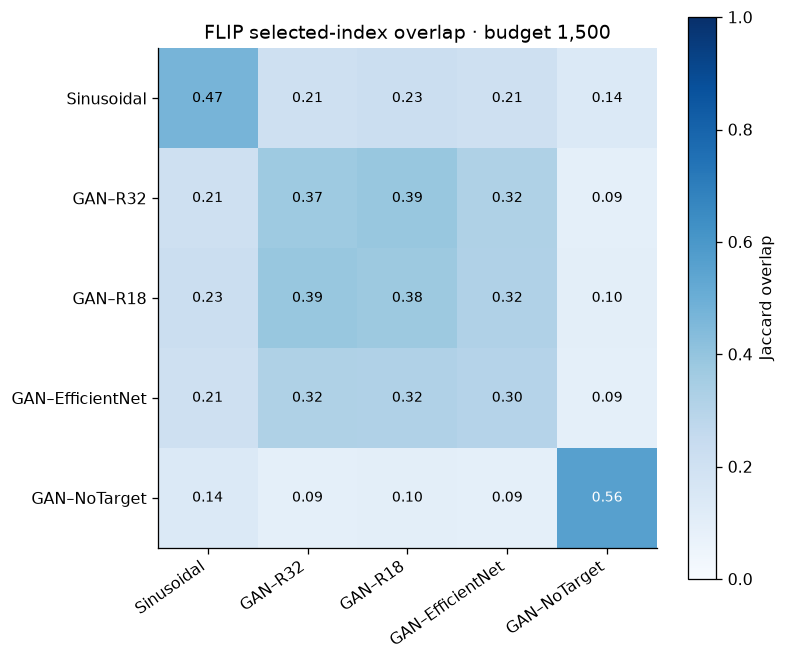

In [25]:
def labelvec(a):
    a=np.asarray(a)
    return a.argmax(axis=1) if a.ndim==2 else a.astype(int).reshape(-1)
LABEL_DATA={}; flip_rows=[]
for v,m in METHODS.items():
    for s in SEEDS:
        d=EXP/m['root']/f"{m['prefix']}_f{s}_labels"
        truth=d/'true.npy'
        if not truth.is_file():continue
        true=labelvec(np.load(truth,allow_pickle=False))
        for b in BUDGETS:
            path=d/f'{b}.npy'
            if not path.is_file():continue
            pred=labelvec(np.load(path,allow_pickle=False))
            if len(pred)!=len(true):raise ValueError(f'Label-length mismatch: {path}')
            ix=np.flatnonzero(pred!=true)
            LABEL_DATA[(v,s,b)]=(set(ix.tolist()),true[ix],pred[ix])
            counts={ 'truck→deer':int(np.sum((true[ix]==SRC)&(pred[ix]==TGT))),
                     'truck→other':int(np.sum((true[ix]==SRC)&(pred[ix]!=TGT))),
                     'other→deer':int(np.sum((true[ix]!=SRC)&(pred[ix]==TGT))),
                     'other→other':int(np.sum((true[ix]!=SRC)&(pred[ix]!=TGT)))}
            flip_rows.append(dict(variant=v,method=m['label'],expert_seed=s,budget=b,
                                  n_flipped=len(ix),**counts))
FLIPS=pd.DataFrame(flip_rows)
if not FLIPS.empty:
    display(FLIPS.groupby(['method','budget'])[['n_flipped','truck→deer']].mean().round(1))
    save_table(FLIPS,'06_flip_composition_per_expert')
    b=1500
    sub=FLIPS[FLIPS.budget.eq(b)]
    cats=['truck→deer','truck→other','other→deer','other→other']
    fig,ax=plt.subplots(figsize=(9,4.6));left=np.zeros(len(METHODS))
    get_cmap = plt.get_cmap
    for idx,cat in enumerate(cats):
        values=np.array([100*sub.loc[sub.variant.eq(v),cat].sum()/max(1,sub.loc[sub.variant.eq(v),'n_flipped'].sum())
                         if sub.variant.eq(v).any() else 0 for v in METHODS])
        ax.barh(range(len(METHODS)),values,left=left,label=cat,height=.7)
        left+=values
    ax.set_yticks(range(len(METHODS)),[METHODS[v]['label'] for v in METHODS]);ax.invert_yaxis()
    ax.set_xlabel('Fraction of flips (%)');ax.set_xlim(0,100)
    ax.set_title('FLIP label solution · 1,500 flips, pooled over Expert seeds')
    ax.legend(ncol=2,fontsize=8,loc='lower right');fig.tight_layout()
    save_figure(fig,'fig07_label_solution_composition');plt.show()

    present=[v for v in METHODS if any((v,s,b) in LABEL_DATA for s in SEEDS)]
    jacc=np.full((len(present),len(present)),np.nan)
    for i,v in enumerate(present):
        for j,w in enumerate(present):
            sims=[]
            for s in SEEDS:
                for t in SEEDS:
                    if (i==j and s>=t) or (i!=j and s!=t):continue
                    if (v,s,b) not in LABEL_DATA or (w,t,b) not in LABEL_DATA:continue
                    A=LABEL_DATA[(v,s,b)][0];B=LABEL_DATA[(w,t,b)][0]
                    sims.append(len(A&B)/len(A|B) if A|B else np.nan)
            if sims:jacc[i,j]=np.nanmean(sims)
    fig,ax=plt.subplots(figsize=(7,6));im=ax.imshow(jacc,vmin=0,vmax=1,cmap='Blues')
    for (i,j),x in np.ndenumerate(jacc):
        if np.isfinite(x):ax.text(j,i,f'{x:.2f}',ha='center',va='center',fontsize=9,
                                   color='white' if x>.55 else 'black')
    ax.set_xticks(range(len(present)),[METHODS[v]['label'] for v in present],rotation=35,ha='right')
    ax.set_yticks(range(len(present)),[METHODS[v]['label'] for v in present])
    ax.grid(False);fig.colorbar(im,ax=ax,label='Jaccard overlap')
    ax.set_title('FLIP selected-index overlap · budget 1,500')
    fig.tight_layout();save_figure(fig,'fig08_flip_overlap_jaccard');plt.show()

## Additional analysis: paired differences and effect size

Because the same Victim seed IDs are used across methods, matched-seed differences in percentage points are informative.

,method,budget,delta_PTA_mean,delta_PTA_sd,delta_CTA_mean,delta_CTA_sd,n
0,GAN–R32,300,49.36,7.03,-0.13,0.50,5
1,GAN–R32,500,20.78,7.17,0.03,0.66,5
2,GAN–R32,1000,6.88,6.43,0.10,0.68,5
3,GAN–R32,1500,2.60,2.72,0.09,0.52,5
4,GAN–R18,300,74.96,11.12,0.20,0.42,5
5,GAN–R18,500,37.06,7.92,0.21,0.31,5
6,GAN–R18,1000,8.90,6.16,0.06,0.54,5
7,GAN–R18,1500,3.14,2.54,0.38,0.54,5
8,GAN–EfficientNet,300,66.80,23.14,0.30,0.24,5
9,GAN–EfficientNet,500,36.12,7.96,0.27,0.26,5


Saved table: 07_paired_vs_sinusoidal
Saved figure: fig09_paired_pta_difference


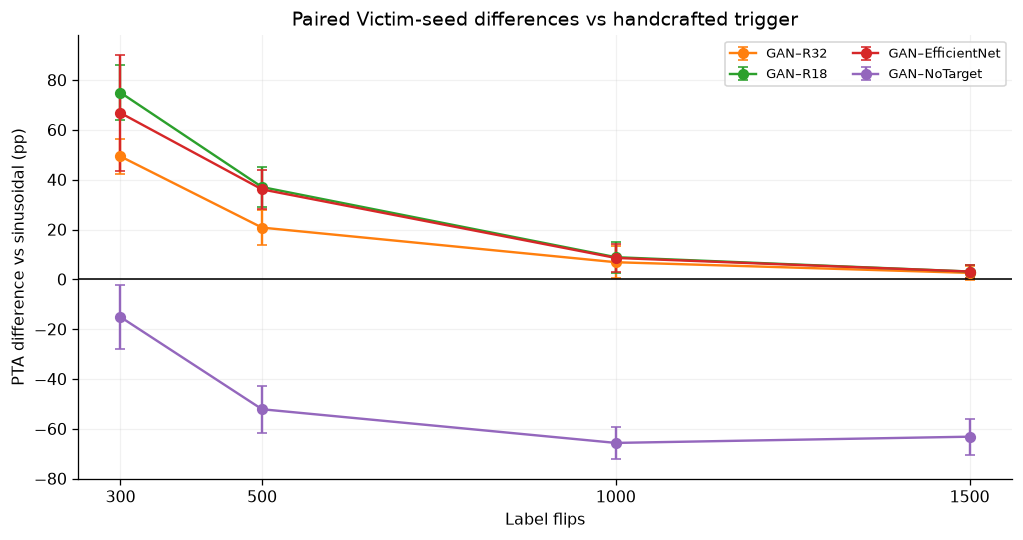

In [26]:
if not RUNS[RUNS.complete & RUNS.variant.eq('sin')].empty:
    base=RUNS[RUNS.complete & RUNS.variant.eq('sin')][['budget','seed','CTA','PTA']].rename(
        columns={'CTA':'CTA_sin','PTA':'PTA_sin'})
    D=RUNS[RUNS.complete & ~RUNS.variant.eq('sin')].merge(base,on=['budget','seed'],validate='many_to_one')
    for metric in ('CTA','PTA'):D[f'delta_{metric}_pp']=D[metric]-D[f'{metric}_sin']
    dsummary=(D.groupby(['method','budget'],sort=False)
              .agg(delta_PTA_mean=('delta_PTA_pp','mean'),delta_PTA_sd=('delta_PTA_pp','std'),
                   delta_CTA_mean=('delta_CTA_pp','mean'),delta_CTA_sd=('delta_CTA_pp','std'),n=('seed','size')).reset_index())
    display(dsummary.round(2));save_table(dsummary,'07_paired_vs_sinusoidal')
    fig,ax=plt.subplots(figsize=(9,4.8))
    for v in METHODS:
        if v=='sin':continue
        sub=D[D.variant.eq(v)].groupby('budget')['delta_PTA_pp'].agg(['mean','std']).reindex(BUDGETS)
        if sub['mean'].notna().any():
            ax.errorbar(BUDGETS,sub['mean'],yerr=sub['std'].fillna(0),fmt='o-',capsize=3,
                        color=COLOR[v],label=METHODS[v]['label'])
    ax.axhline(0,color='black',lw=1);ax.set_xticks(BUDGETS)
    ax.set(xlabel='Label flips',ylabel='PTA difference vs sinusoidal (pp)',
           title='Paired Victim-seed differences vs handcrafted trigger')
    ax.legend(ncol=2,fontsize=8);fig.tight_layout();save_figure(fig,'fig09_paired_pta_difference');plt.show()

## Additional analysis: trigger energy and surrogate diagnostics

The GAN methods have similar nominal RMS, whereas NoTarget has a substantially weaker learned perturbation. This creates a magnitude confound in any interpretation of NoTarget versus targeted GANs.

Saved figure: fig10_trigger_rms


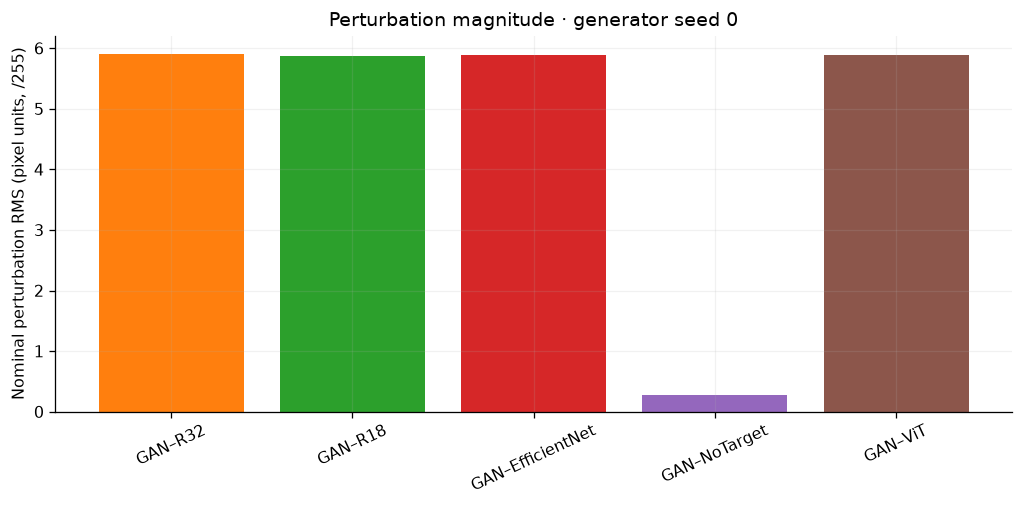

ViT surrogate diagnostics:
{
  "seed": 0,
  "epochs": 30,
  "architecture": "ViT patch8 dim192 depth6 heads6",
  "optimizer": "SGD",
  "clean_test_accuracy": 54.34
}


In [27]:
if not TRIGGER.empty:
    fig,ax=plt.subplots(figsize=(9,4.5))
    df=TRIGGER.dropna(subset=['nominal_RMS_px'])
    ax.bar(df.method,df.nominal_RMS_px,color=[COLOR[v] for v in df.variant])
    ax.set(ylabel='Nominal perturbation RMS (pixel units, /255)',
           title='Perturbation magnitude · generator seed 0')
    ax.tick_params(axis='x',rotation=25);fig.tight_layout()
    save_figure(fig,'fig10_trigger_rms');plt.show()
metric_path=NOISE/'surrogate_vit_metrics.json'
if metric_path.is_file():
    print('ViT surrogate diagnostics:')
    print(json.dumps(json.loads(metric_path.read_text()),indent=2))
else:
    print('ViT surrogate metrics not yet available.')